In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
import scipy as sp
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import gaussian
import time
import utils
import os

### Loading in data, can be combined with GetTimeStream notebook

In [13]:
utils.retrieval(17)

In [2]:
def recon_on_many(itr, fmix=110e6, units=1e6, magnitude=False, rel=False, B=20, C=3):
    path = '/nfs/roberts/pi/pi_kmh66/spreadsheetData/SpreadsheetRow51_UNetScattering_CCA/Trap_CCA_long_trap_44_UNetScattering_1/Trap_CCA_long_trap_44_UNetScattering_1/results/'
    files = list(os.scandir(path))
    length = len(files)
    itr = itr
    i = -1
    error = np.zeros((2, itr-1))


    
    while i < itr:
        filepath = path
        print(filepath)
        
        if not files[i].is_dir():
            continue
        else:
            i += 1
            print(f"{i}/{itr}")
    
            name = files[i].name
            filepath = filepath + name
    
            subfiles = os.scandir(filepath)
    
            for file in subfiles:
                if file.name.endswith('.egg'):
                    eggfilepath = filepath+"/"+file.name
    
            jsonfilepath = filepath+'/LocustEventProperties.json'
    
            with open(jsonfilepath, 'r') as file:
                metadata = json.load(file)
    
            file = EggFileReader(eggfilepath)
            stream = file.load_ts_stream()[0][0][0]
            I_data = stream.real
            Q_data = stream.imag
    
        
            if (i-1) % 10 == 0: print(f"{i}/{itr-1}")
            file_id = obj[i].name[2:-4]
            fs = float(metadata['run-parameters']['sampling-freq-mega-hz'])*units
            f = metadata['0']['0']['output-avg-frequency']
            start = metadata['0']['0']['start-time']
            end = metadata['0']['0']['end-time']
            
            actual = (f - fmix)/1e6
        
            idx = int(fs*start)
            edx = int(fs*end)
            
            data = I_data[idx:edx] + 1j*Q_data[idx:edx]
            T  = float(data.size)/fs
            N  = len(data)
            t  = np.arange(N) / fs
            signal_locust = data * (-1.0)**np.arange(N)
    
            signal = signal_locust * np.exp(-1j * 2*np.pi * fmix * t)
            
            t_center = 0.0015     # seconds -- time where there is a track
            window   = 5e-3       # 5 ms around it
            i0 = max(0, int((t_center - window/2) * fs))
            i1 = min(N, int((t_center + window/2) * fs))
            signal = signal[i0:i1]
            signal_locust = signal_locust[i0:i1]
            N = len(signal)
            t = np.arange(N) / fs
        
            ### STFT
            win_len = min(1024, N // 8)     
            hop     = max(1, win_len // 8)
            
            win = gaussian(win_len, std=win_len/6, sym=True)
            SFT = ShortTimeFFT(win, hop=hop, fs=fs, fft_mode='centered',
                               scale_to='magnitude')
            Sxx = SFT.stft(signal)
            f_stft = SFT.f
            t_stft = SFT.t(N)
    
            ### CWT
            wavelet = f'cmor{B}-{C}'
            
            fmin     = 50e5
            fmax     = 50e6
            n_voices = 96
             
            freqs_pos = np.logspace(np.log10(fmin), np.log10(fmax), n_voices)
            scales    = pywt.frequency2scale(wavelet, freqs_pos / fs)
    
            coefs, f_returned = pywt.cwt(
                signal, scales, wavelet, sampling_period=1/fs, method='fft'
            )
            mag = np.abs(coefs)
    
            t_cwt = np.arange(mag.shape[1]) / fs
            idx_cwt = N//2
            #print("At CWT time:", t_cwt[idx_cwt]*1e3, "ms")
            idx_stft = max(np.where(np.round(t_stft*1e3 - t_cwt[idx_cwt]*1e3, 3) == 0.0)[0])
            #print("At STFT time:", t_stft[idx_stft]*1e3, "ms")
            
            magcwt = mag[:, idx_cwt]
            magstft = np.abs(Sxx[:, idx_stft])
            
            f_CWT = freqs_pos[np.argmax(magcwt)]/1e6
            #print(f"\nFrequency CWT: {f_CWT}, \nDifference Error: {f_CWT-actual}\n")
            
            f_STFT = f_stft[np.argmax(magstft)]/1e6
            #print(f"Frequency STFT: {f_STFT}, \nDifference Error: {f_STFT-actual}")
                
            if rel: denom=actual
            else: denom=1
        
            if magnitude:
                error[0,i-1]=np.abs((f_CWT-actual)/denom)
                error[1,i-1]=np.abs((f_STFT-actual)/denom)
            else:
                error[0,i-1] = (f_CWT-actual)/denom
                error[1,i-1] = (f_STFT-actual)/denom
            
        print("COMPLETE")    
        np.save(f"error_{itr}_mag{magnitude}_B{B}_C{C}", error)

In [3]:
recon_on_many(1, B=15, C=3)

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)


KeyboardInterrupt



KeyboardInterrupt: 

[[-0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945 -0.20758945
  -0.20758945 -0.20758945 -0.20758945 

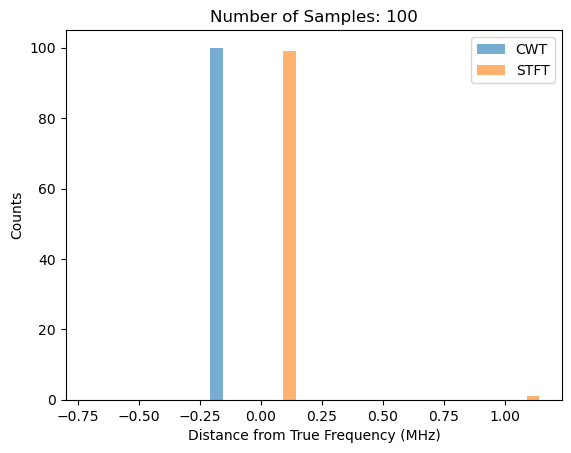

[[1.64405128 2.28606858 2.18475055 3.07165967 3.1164144  1.48084585
  2.29947433 2.27915555 3.05362636 2.29874942 2.30628975 2.24948017
  2.47055234 1.73973235 1.93949704 3.08933081 1.97851643 1.48710615
  2.29932858 3.08055461 2.29855582 1.47561417 2.28523274 2.25705702
  3.05233028 3.06634107 3.04250138 3.0297191  1.95601756 2.2979741
  2.25954764 1.95419929 2.26579012 1.4890395  1.93934264 2.25058515
  3.06694411 1.49000496 2.18526587 1.90370693 1.89594055 2.24858548
  1.89275932 1.88856958 1.88907354 2.26079613 1.89388103 1.90208938
  3.05278063 2.25926045 3.31272397 1.88937688 2.28439523 2.49979347
  2.46523635 1.89176704 1.89627406 1.89643859 2.25144164 1.89843963
  1.90139734 3.03825963 1.90118906 2.27724545 3.07116218 1.90251503
  1.90097692 1.89511316 2.29438601 3.07009268 2.30096441 1.94090409
  1.93777852 1.88973873 2.25124319 1.88800653 1.94366677 3.05488243
  1.93817764 2.27447146 1.8888687  1.89251897 1.94143233 1.94920432
  2.26595612 1.93998011 1.94471794 1.93830409 1.9

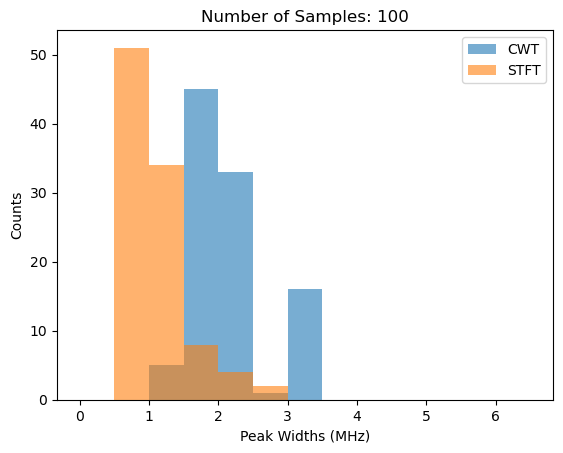

In [19]:
itr = 100
err = np.load(f"error_{itr}_magFalse_B20_C3.npy")
print(err)
print("CWT | STFT\nMean")
print(np.mean(err, axis=1))
print("STD")
print(np.std(err, axis=1))

bins=20

plt.hist(err[0], label="CWT", bins=bins, alpha=0.6)
plt.hist(err[1], label="STFT",bins=bins, alpha=0.6)
plt.legend()
plt.xlabel("Distance from True Frequency (MHz)")
plt.ylabel("Counts")
plt.title(f"Number of Samples: {itr}")
plt.show()

widths = np.load(f"FWHMs_{itr}_magFalse_B20_C3.npy")/1e6
print(widths)
print("CWT | STFT\nMean")
print(np.mean(widths, axis=1))
print("STD")
print(np.std(widths, axis=1))

bins=np.arange(0, 7, 0.5)

plt.hist(widths[0], label="CWT", bins=bins, alpha=0.6)
plt.hist(widths[1], label="STFT",bins=bins, alpha=0.6)
plt.legend()
plt.xlabel("Peak Widths (MHz)")
plt.ylabel("Counts")
plt.title(f"Number of Samples: {itr}")
plt.show()


In [20]:
I = np.load("data/I_1070126072228-023.npy")
metadata = utils.get_quantities("data/metadata_1070126072228-023.json")
f_actual = metadata[2]
fs = float(metadata[0])*1e6
Q = np.load("data/Q_1070126072228-023.npy")

In [21]:
I.size

3500000

In [22]:
start = metadata[1][0, 0]
end = metadata[1][1, 0]
print(start, end)
idx = int(fs*start)
edx = int(fs*end)
print(idx, edx)
#idx = 0
#edx = -1

0.000406551 0.00440655
163840 1775839


### Signal parameters

In [23]:
signal_raw = I[idx:edx].astype(np.float64) + 1j * Q[idx:edx].astype(np.float64)
fs = 403e6                      
T  = float(signal_raw.size)/fs
N  = signal_raw.size
t  = np.arange(N) / fs

### Downmixing signal

In [24]:
signal_locust = signal_raw * (-1.0)**np.arange(N)

ft = 31e6
f_mix = f_actual-ft                    # Hz -- tracks will land at ~142 - 135 = 7 MHz
signal = signal_locust * np.exp(-1j * 2*np.pi * f_mix * t)
 
print(f"Loaded {N} complex samples, {T*1e3:.3f} ms at {fs/1e6:.1f} MS/s")
print(f"Mixing down by {f_mix/1e6:.1f} MHz; tracks should land at "
      f"{(141.77e6 - f_mix)/1e6:.1f} MHz post-mix")

t_center = 0.0015     # seconds -- time where there is a track
window   = 5e-3       # 5 ms around it
i0 = max(0, int((t_center - window/2) * fs))
i1 = min(N, int((t_center + window/2) * fs))
signal = signal[i0:i1]
signal_locust = signal_locust[i0:i1]
N = len(signal)
t = np.arange(N) / fs
print(f"Sliced to {N} samples = {N/fs*1e3:.2f} ms")

Loaded 1611999 complex samples, 4.000 ms at 403.0 MS/s
Mixing down by 111.5 MHz; tracks should land at 30.3 MHz post-mix
Sliced to 1611999 samples = 4.00 ms


### Plotting STFT, can be replaced with STFT_viz notebook

Record length    : 1611999 samples = 4.000 ms
Window length    : 1024 samples = 2.54 us
Time resolution  : ~2.54 us per STFT frame
Freq resolution  : ~393.55 kHz per bin


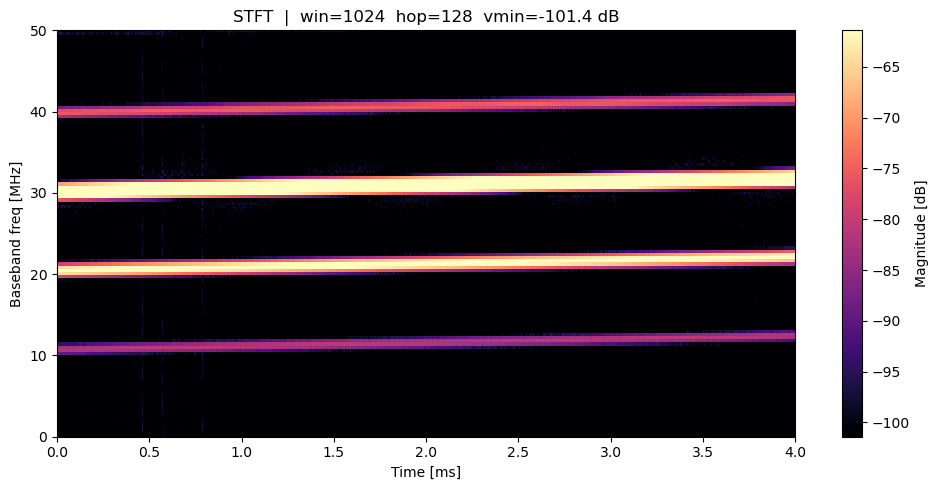

In [25]:
N = len(signal)
win_len = min(1024, N // 8)     
hop     = max(1, win_len // 8)

print(f"Record length    : {N} samples = {N/fs*1e3:.3f} ms")
print(f"Window length    : {win_len} samples = {win_len/fs*1e6:.2f} us")
print(f"Time resolution  : ~{win_len/fs*1e6:.2f} us per STFT frame")
print(f"Freq resolution  : ~{fs/win_len/1e3:.2f} kHz per bin")

win = gaussian(win_len, std=win_len/6, sym=True)
SFT = ShortTimeFFT(win, hop=hop, fs=fs, fft_mode='centered',
                   scale_to='magnitude')
Sxx = SFT.stft(signal)
f_stft = SFT.f
t_stft = SFT.t(N)

mag_db = 20*np.log10(np.abs(Sxx) + 1e-12)
vmax = np.percentile(mag_db, 99.5)
vmin = vmax - 40          # 40 dB dynamic range

fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(t_stft*1e3, f_stft/1e6, mag_db,
                    shading='auto', cmap='magma', vmin=vmin, vmax=vmax)
ax.set_xlabel('Time [ms]'); ax.set_ylabel('Baseband freq [MHz]')
ax.set_title(f'STFT  |  win={win_len}  hop={hop}  vmin={vmin:.1f} dB')
#ax.set_xlim(0.0, 2.0)
ax.set_ylim(0, 50)
fig.colorbar(pcm, ax=ax, label='Magnitude [dB]')
plt.tight_layout(); plt.show()

### Wavelet parameter choices

In [14]:
B, C    = 20.0, 3.0
wavelet = f'cmor{B}-{C}'
 
# Band of interest: a bit below the lowest post-mix track to a bit above
# the highest. Post-mix tracks are at ~7 MHz; give generous margin.
fmin     = 50e5               # 500 kHz; stay clear of DC artifacts
fmax     = 50e6               # covers tracks + sidebands with headroom
n_voices = 96
 
freqs_pos = np.logspace(np.log10(fmin), np.log10(fmax), n_voices)
scales    = pywt.frequency2scale(wavelet, freqs_pos / fs)
 
assert scales.min() >= 1.0, (
    f"Smallest scale {scales.min():.2f} < 1. Lower fmax or increase fs."
)
 
sigma_t_fmin  = np.sqrt(B/2) * C / fmin
sigma_f_10M   = 10e6 / (np.pi * C * np.sqrt(2*B))
sigma_f_fmax  = fmax / (np.pi * C * np.sqrt(2*B))
print(f"Wavelet        : {wavelet}")
print(f"Scale range    : {scales.min():.2f} -> {scales.max():.2f}")
print(f"Freq range     : {fmin/1e6:.2f} -> {fmax/1e6:.2f} MHz")
print(f"sigma_t @ fmin : {sigma_t_fmin*1e6:.2f} us  (tracks ~1000-5000 us)")
print(f"sigma_f @ 10M  : {sigma_f_10M/1e3:.1f} kHz  (at track location)")
print(f"sigma_f @ fmax : {sigma_f_fmax/1e3:.1f} kHz")

Wavelet        : cmor20.0-3.0
Scale range    : 24.18 -> 241.80
Freq range     : 5.00 -> 50.00 MHz
sigma_t @ fmin : 1.90 us  (tracks ~1000-5000 us)
sigma_f @ 10M  : 167.8 kHz  (at track location)
sigma_f @ fmax : 838.8 kHz


### Creating scaleogram

In [9]:
coefs, f_returned = pywt.cwt(
    signal, scales, wavelet, sampling_period=1/fs, method='fft'
)
mag = np.abs(coefs)
 
print(f"Scaleogram shape: {mag.shape}  (freq bins x time samples)")
print(f"Memory: {mag.nbytes/1e6:.1f} MB")

Scaleogram shape: (96, 282708)  (freq bins x time samples)
Memory: 217.1 MB


### Finding Sidebands + Reconstruction Error

In [10]:
t_plot = np.arange(mag.shape[1]) / fs
idx = N//5
print("At time:", t_plot[idx]*1e3, "ms")
print("We have frequency bands of:")
print(freqs_pos[np.where(mag[:, idx] >= 1e-4)[0]]/1e6)

At time: 0.1403002481389578 ms
We have frequency bands of:
[ 5.          8.1188837  10.09794875 10.34569041 10.59951012 18.96345095
 19.42869759 19.90535853 20.39371379 20.8940503  21.40666199 21.93185003
 23.02119688 25.36490045 26.62476565 27.27797391 28.63286075 29.33533533
 30.05504432 30.79241055 31.54786722 32.32185816 33.92727287 34.75963981
 35.61242792 36.48613822 37.38128401 38.29839117 40.20065806 41.18693535
 42.19740983 44.29333952]


In [17]:
f_target = ft/1e6
print("Target Frequency:", f_target)

t_cwt = np.arange(mag.shape[1]) / fs
idx_cwt = 200000
print("At CWT time:", t_cwt[idx_cwt]*1e3, "ms")
idx_stft = max(np.where(np.round(t_stft*1e3 - t_cwt[idx_cwt]*1e3, 3) == 0.0)[0])
print("At STFT time:", t_stft[idx_stft]*1e3, "ms")

magcwt = mag[:, idx_cwt]
magstft = np.abs(Sxx[:, idx_stft])

f_CWT = freqs_pos[np.argmax(magcwt)]/1e6
print(f"\nFrequency CWT: {f_CWT}, \nDifference Error: {f_CWT-f_target}\n")

f_STFT = f_stft[np.argmax(magstft)]/1e6
print(f"Frequency STFT: {f_STFT}, \nDifference Error: {f_STFT-f_target}")

Target Frequency: 31.0
At CWT time: 0.49627791563275436 ms
At STFT time: 0.49675434243176175 ms

Frequency CWT: 30.79241055330133, 
Difference Error: -0.20758944669866963

Frequency STFT: 31.0908203125, 
Difference Error: 0.0908203125


### Marginalization

In [31]:
def map_index_to_x(x, a, out):
    returns = []
    for i in out:
        subreturn = []
        for j in i:
            idx = int(j)
            diff = j-idx
            subreturn.append(x[idx] + a*diff)
        returns.append(subreturn)

    returns = np.array(returns).T

    return returns

[31 59 75 87]
Peak Frequencies in order: [10.59951012 20.8940503  30.79241055 41.18693535]
Predicted Widths in Order: [2.18904406e-06 1.93486616e-06 1.87420532e-06 1.54064874e-06]


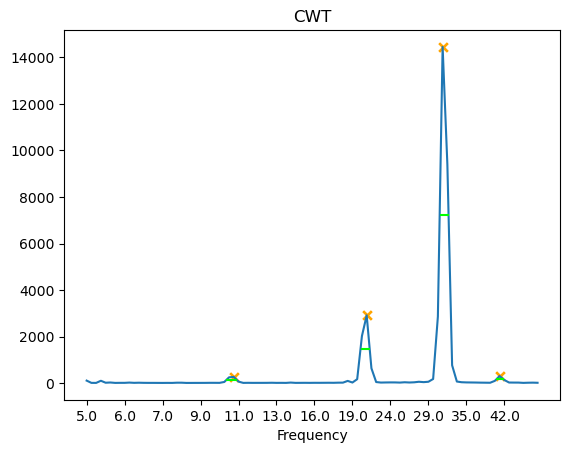

[10599510.11924803 20894050.30147109 30792410.55330133 41186935.34785505]
0.0007015062034739454
0.0007025707196029776


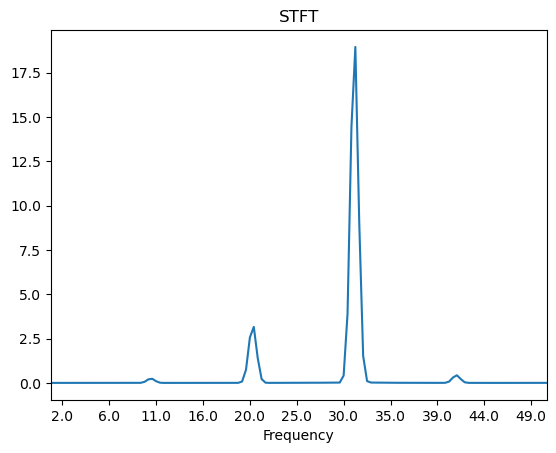

In [60]:
from scipy.signal import find_peaks, peak_widths

end = metadata[1][1, 0]
idx_cwt = max(np.where(np.round(t_cwt - end, 1) == 0.0)[0])
m_CWT = np.sum(mag[:, :idx_cwt], axis=1)
fullxrange = np.array(range(len(m_CWT)))

plt.plot(m_CWT)
plt.xlabel("Frequency")
plt.title("CWT")
xrange = np.arange(0, len(m_CWT), 8)
plt.xticks(xrange, np.round(freqs_pos[xrange]/1e6, 0))

a_f = 1
n = m_CWT
peaks = find_peaks(n)[0]
peaks = peaks[np.where(n[peaks] >= 100)[0]]
p_idx = n[peaks]
print(peaks)
print(f"Peak Frequencies in order: {freqs_pos[peaks]/1e6}")
widths = np.array(peak_widths(n, peaks, rel_height=0.5))

f_bounds = map_index_to_x(fullxrange, a_f, widths[2:])
f_widths = np.zeros((len(f_bounds[:, 0]), 4))
f_widths[:, 0] = f_bounds[:, 1] - f_bounds[:, 0]
f_widths[:, 1] = widths[1]
f_widths[:, 2:] = f_bounds
    
print(f"Predicted Widths in Order: {f_widths[:, 0]/1e6}")
for j in range(len(f_bounds[:, 0])):
    plt.hlines(*f_widths[j, 1:], color="lime")
    plt.scatter(fullxrange[peaks], n[peaks],color="orange", marker="x")
plt.show()

print(freqs_pos[peaks])

print(t_plot[idx_cwt])

idx_stft = max(np.where(np.round(t_stft - end, 2) == 0 )[0])
print(t_stft[idx_stft])
m_STFT = np.sum(np.abs(Sxx)[:, :idx_stft], axis=1)
plt.plot(m_STFT)
plt.xlabel("Frequency")
plt.title("STFT")
xrange = np.arange(0, len(m_STFT), 12)
plt.xticks(xrange,np.round(f_stft[xrange]/1e6, 0))
plt.xlim(min(np.where(f_stft/1e6 > 0)[0]), min(np.where(f_stft/1e6 - 50 > 1e-3)[0]))
plt.show()



### Plotting scaleogram

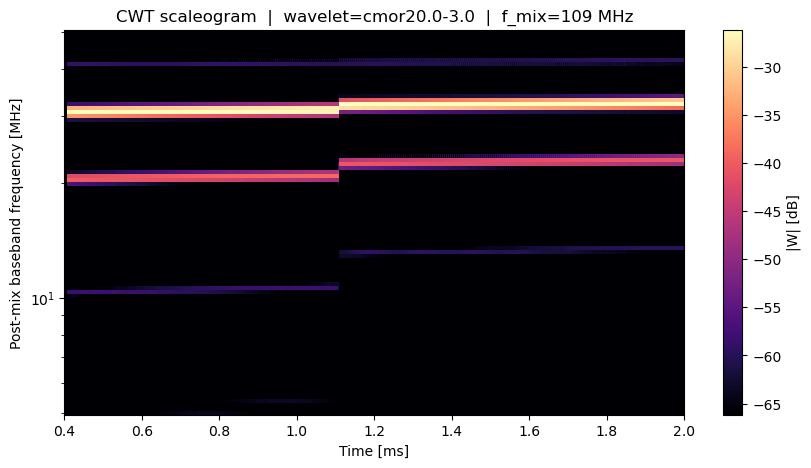

In [45]:
t_plot = np.arange(mag.shape[1]) / fs
mag_db = 20*np.log10(mag + 1e-12)
vmax   = np.percentile(mag_db, 99.5)
vmin   = vmax - 40
 
fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(t_plot*1e3, freqs_pos/1e6, mag_db,
                    shading='auto', cmap='magma', vmin=vmin, vmax=vmax)
ax.set_xlabel('Time [ms]')
ax.set_ylabel('Post-mix baseband frequency [MHz]')
ax.set_yscale('log')
plt.xlim(0.4, 2.0)
ax.set_title(f'CWT scaleogram  |  wavelet={wavelet}  |  f_mix={f_mix/1e6:.0f} MHz')
fig.colorbar(pcm, ax=ax, label='|W| [dB]')
plt.show()

### Plotting wavelet properties to help tune parameters

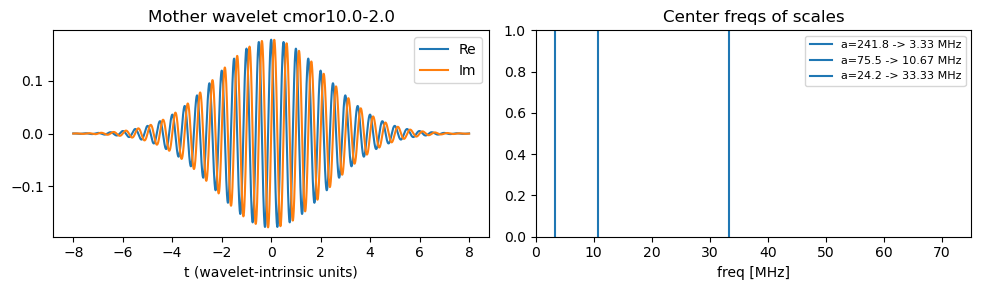

In [26]:
B, C    = 10.0, 2.0
wavelet = f'cmor{B}-{C}'
wav     = pywt.ContinuousWavelet(wavelet)
psi, x  = wav.wavefun(level=12)
 
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(x, np.real(psi), label='Re')
axes[0].plot(x, np.imag(psi), label='Im')
axes[0].set_title(f'Mother wavelet {wavelet}'); axes[0].legend()
axes[0].set_xlabel('t (wavelet-intrinsic units)')
 
for a in [scales[0], scales[len(scales)//2], scales[-1]]:
    fc = pywt.scale2frequency(wavelet, a) * fs
    axes[1].axvline(fc/1e6, label=f'a={a:.1f} -> {fc/1e6:.2f} MHz')
axes[1].set_xlabel('freq [MHz]'); axes[1].set_title('Center freqs of scales')
axes[1].legend(fontsize=8);
axes[1].set_xlim(0, fmax*1.5/1e6)
plt.tight_layout(); plt.show()